# Support Vector Machines – forelesning 2: Python-kode med forklaringer

Dette skriptet er en Python-versjon av R-skriptet til forelesning 2.
Som i forelesning 1 er det skrevet i *percent*-format: hver `# %%` starter en kodecelle, og `# %% [markdown]` starter en tekstcelle.
Du kan kjøre cellene én og én i VS Code, Spyder eller PyCharm, kjøre hele filen som et skript, eller åpne notebook-versjonen (`.ipynb`) i Jupyter.

**Om tallene:** Python og R bruker ulike tilfeldighetsgeneratorer, så de simulerte dataene og tallene er ikke identiske med R-versjonen.
Frøene er valgt slik at mønsteret og konklusjonene er de samme.

**Fra R til Python – nytt i denne forelesningen:**

| R | Python |
|:--|:--|
| `svm(..., kernel = "radial", gamma = g)` | `SVC(kernel="rbf", gamma=g)` |
| `predict(mod, ..., decision.values = TRUE)` | `mod.decision_function(...)` |
| `mod$coefs`, `mod$SV`, `-mod$rho` | `dual_coef_`, `support_vectors_`, `intercept_` |
| `glm(..., family = binomial)` | `smf.logit(...)` fra `statsmodels` |
| `contour()` | `plt.contour()` |

## 1. Pakker og simulerte ringdata

I tillegg til pakkene fra forelesning 1 bruker vi `statsmodels` til logistisk regresjon.
Installer med `pip install numpy pandas matplotlib scikit-learn statsmodels`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.metrics import roc_auc_score
import statsmodels.formula.api as smf

Vi lager 240 punkter: 120 i et sentrum og 120 i en ring rundt.
Punktene lages i *polarkoordinater*: en vinkel (retning fra origo) og en radius (avstand fra origo).
Deretter regner vi om til vanlige koordinater med $x_1 = r\cos\theta$ og $x_2 = r\sin\theta$.
Slik er det lett å styre hvor langt fra sentrum hver klasse ligger.

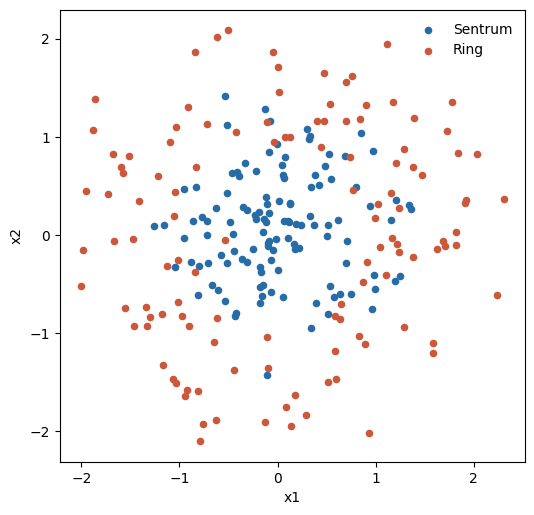

In [2]:
rng = np.random.default_rng(52)
n2 = 240

# Klassene: de første 120 er «Sentrum», de neste 120 er «Ring»
klasse = np.repeat(["Sentrum", "Ring"], n2 // 2)

# Vinkel: tilfeldig retning rundt hele sirkelen (0 til 2*pi radianer)
vinkel = rng.uniform(0, 2 * np.pi, n2)

# Radius: sentrum ligger 0–1,2 fra origo, ringen 0,9–2,1.
# Intervallene overlapper mellom 0,9 og 1,2, så klassene kan ikke skilles perfekt
radius = np.concatenate([rng.uniform(0, 1.2, n2 // 2), rng.uniform(0.9, 2.1, n2 // 2)])

dat_ring = pd.DataFrame({
    # Fra polarkoordinater til x1 og x2, pluss litt støy (sd = 0,2)
    "x1": radius * np.cos(vinkel) + rng.normal(0, 0.2, n2),
    "x2": radius * np.sin(vinkel) + rng.normal(0, 0.2, n2),
    "y": klasse,
})

FARGE = {"Sentrum": "#276ca6", "Ring": "#cc583b"}

fig, ax = plt.subplots(figsize=(6, 6))
for navn, f in FARGE.items():
    del_ = dat_ring[dat_ring["y"] == navn]
    ax.scatter(del_["x1"], del_["x2"], c=f, s=20, label=navn)
ax.set_aspect("equal")   # Lik skala, så sirkelen ser rund ut
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend(loc="upper right", frameon=False)
plt.show()

**Slik leser du figuren:**
De blå punktene (sentrum) ligger samlet rundt origo, og de røde (ringen) ligger rundt dem.
Ingen rett linje kan skille de to klassene: uansett hvor vi legger linjen, får vi både blå og røde punkter på hver side.
I overgangssonen blander klassene seg, så heller ikke en buet grense kan klassifisere alle punktene riktig.

## 2. Trening og test, og tuning med kryssvalidering

Vi deler data i 70 % trening og 30 % test med `train_test_split()`.
Med `stratify=` blir delingen *stratifisert*: begge delene får samme andel av hver klasse.
I R måtte vi gjøre dette for hånd med `split()` og `lapply()`.

In [3]:
train_ring, test_ring = train_test_split(
    dat_ring, test_size=0.3,
    stratify=dat_ring["y"],   # Samme klassefordeling i trening og test
    random_state=94,          # Frø for reproduserbar deling
)

# scikit-learn vil ha prediktorene som en matrise X og klassene som en vektor y
X_train, y_train = train_ring[["x1", "x2"]].to_numpy(), train_ring["y"].to_numpy()
X_test, y_test = test_ring[["x1", "x2"]].to_numpy(), test_ring["y"].to_numpy()

print("Trening:", dict(train_ring["y"].value_counts()))   # 84 Sentrum og 84 Ring
print("Test:   ", dict(test_ring["y"].value_counts()))    # 36 Sentrum og 36 Ring

Trening: {'Sentrum': np.int64(84), 'Ring': np.int64(84)}
Test:    {'Sentrum': np.int64(36), 'Ring': np.int64(36)}


Vi tuner to modeller med femfolds kryssvalidering (CV) på treningsdataene:

- en **lineær SVC**, der vi bare velger `C`;
- en **radial SVM**, der vi velger både `C` og `gamma`. `GridSearchCV()` prøver alle $5 \times 4 = 20$ kombinasjoner.

Radialkjernen heter `"rbf"` i `scikit-learn` (*radial basis function*), men er den samme som `"radial"` i `e1071`.
Begge modellene er en pipeline med `StandardScaler()` først, slik at skaleringen gjøres på nytt inne i hver fold.
Begge bruker samme fold-inndeling (`cv`), slik at sammenligningen blir rettferdig.

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=95)   # Samme folder for begge modellene

cv_rett = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel="linear")),
    param_grid={"svc__C": [0.1, 1, 10]},
    cv=cv,
).fit(X_train, y_train)

cv_radial = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    param_grid={"svc__C": [0.01, 0.1, 1, 10, 100],   # Hvor dyrt det er å bryte marginen
                "svc__gamma": [0.05, 0.2, 1, 5]},    # Hvor raskt likheten avtar med avstanden
    cv=cv,
).fit(X_train, y_train)

print("Lineær SVC: ", cv_rett.best_params_)
print("Radial SVM: ", cv_radial.best_params_)

Lineær SVC:  {'svc__C': 1}
Radial SVM:  {'svc__C': 1, 'svc__gamma': 0.2}


**Slik leser du output:**
For den lineære modellen velges `C = 1`, og for den radiale velges `C = 1` og `gamma = 0,2`.

In [5]:
# CV-feil for alle 20 kombinasjoner. Vi sorterer etter feil og viser de seks beste
perf = pd.DataFrame({
    "C": cv_radial.cv_results_["param_svc__C"],
    "gamma": cv_radial.cv_results_["param_svc__gamma"],
    "error": 1 - cv_radial.cv_results_["mean_test_score"],   # CV-feil = 1 - treffrate
    "dispersion": cv_radial.cv_results_["std_test_score"],   # Standardavvik over foldene
})
perf.sort_values("error").head(6)

,C,gamma,error,dispersion
9,1.0,0.20,0.154545,0.050460
6,0.1,1.00,0.172727,0.039427
10,1.0,1.00,0.178253,0.040636
16,100.0,0.05,0.178253,0.055094
12,10.0,0.05,0.178431,0.064407
13,10.0,0.20,0.184492,0.060013


**Slik leser du output:**
`error` er gjennomsnittlig andel feilklassifiserte observasjoner i valideringsfoldene (CV-feil).
`dispersion` er standardavviket til feilraten over de fem foldene, et mål på usikkerheten.

De seks beste kombinasjonene har CV-feil mellom 0,155 og 0,184.
Forskjellene er små sammenlignet med `dispersion` (0,04–0,06).
`C` varierer fra 0,1 til 100 og `gamma` fra 0,05 til 1 blant de beste: høy `C` går sammen med lav `gamma` og omvendt.
Vi lærer altså mer av *området* som fungerer enn av akkurat den kombinasjonen som vant.

## 3. Tegne beslutningsgrensen

En radial SVM gir en buet grense, og den kan vi ikke tegne som en rett linje.
I stedet regner vi ut skåren $f(x)$ i et tett rutenett av punkter med `decision_function()` og tegner *nivåkurver* med `plt.contour()`:

- nivåkurven $f(x) = 0$ er beslutningsgrensen,
- nivåkurvene $f(x) = \pm 1$ er marginene.

Dette er samme idé som høydekoter på et kart.

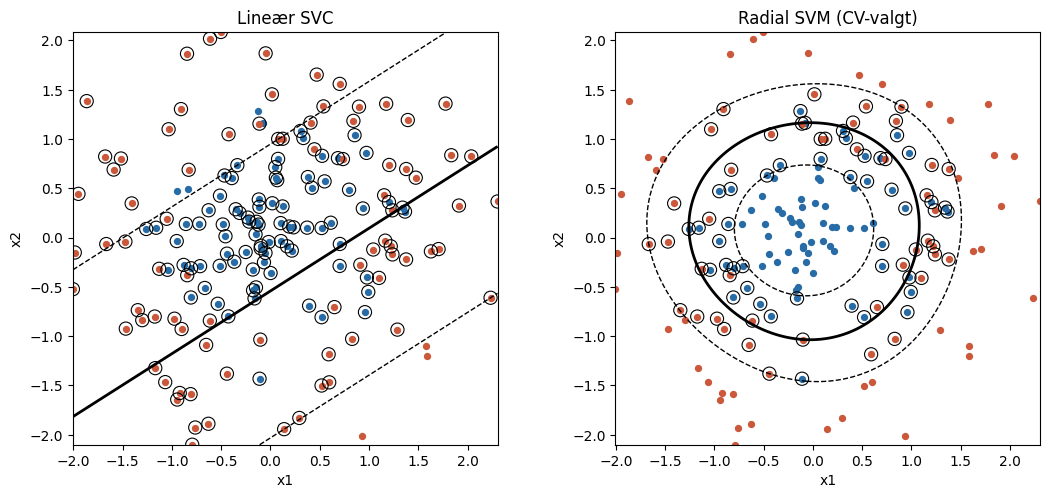

In [6]:
def tegn_grense(mod, data, ax, tittel=""):
    # 150 x 150 = 22 500 punkter som dekker området der dataene ligger
    g1 = np.linspace(data["x1"].min(), data["x1"].max(), 150)
    g2 = np.linspace(data["x2"].min(), data["x2"].max(), 150)
    G1, G2 = np.meshgrid(g1, g2)                   # Alle kombinasjoner av g1 og g2
    rutenett = np.column_stack([G1.ravel(), G2.ravel()])

    # Beslutningsverdien f(x) i hvert rutenettpunkt, lagt tilbake i rutenettets form
    f = mod.decision_function(rutenett).reshape(G1.shape)

    for navn, farge in FARGE.items():
        del_ = data[data["y"] == navn]
        ax.scatter(del_["x1"], del_["x2"], c=farge, s=18)

    ax.contour(G1, G2, f, levels=[0], colors="black", linewidths=2)                     # Beslutningsgrensen
    ax.contour(G1, G2, f, levels=[-1, 1], colors="black", linewidths=1, linestyles="--")  # Marginene

    # Ring rundt støttevektorene. mod[-1] er siste steg i pipelinen, altså SVC-en
    sv = mod[-1].support_
    ax.scatter(data["x1"].iloc[sv], data["x2"].iloc[sv], s=90,
               facecolors="none", edgecolors="black", linewidths=0.8)

    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(tittel)


fig, akser = plt.subplots(1, 2, figsize=(11, 5))
tegn_grense(cv_rett.best_estimator_, train_ring, akser[0], "Lineær SVC")
tegn_grense(cv_radial.best_estimator_, train_ring, akser[1], "Radial SVM (CV-valgt)")
plt.tight_layout()
plt.show()

**Slik leser du figuren:**
Den lineære SVC-en (venstre) legger en rett linje gjennom skyen.
Marginene er svært brede, og nesten alle punktene har ring: de er støttevektorer.
Det er et tegn på at en rett linje ikke klarer å skille klassene.

Den radiale SVM-en (høyre) har en lukket, omtrent sirkelformet grense rundt sentrum, som svarer godt til hvordan vi simulerte dataene.
Støttevektorene ligger i overgangssonen mellom klassene.
Punkter langt inne i sentrum eller langt ute i ringen har ingen ring og påvirker ikke grensen.

`cv_rett.best_estimator_` er den beste pipelinen, tilpasset på nytt på hele treningsdelen; den tilsvarer `best.model` i R.

## 4. Overtilpasning: hva skjer med `gamma = 50`?

Vi tilpasser en bevisst overtilpasset modell med svært høy `gamma` og `C`.
Høy `gamma` gjør at hvert punkt bare påvirker et lite område rundt seg, og høy `C` gjør brudd svært dyre.

In [7]:
mod_overtilp = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=100, gamma=50)).fit(X_train, y_train)

# Vi samler de tre modellene i en ordbok, så vi kan behandle dem likt i løkker
modeller = {
    "Lineær SVC": cv_rett.best_estimator_,
    "Radial SVM (CV-valgt)": cv_radial.best_estimator_,
    "Radial SVM (gamma 50)": mod_overtilp,
}


def treff(mod, X, y):
    """Andel riktige: == gir True ved riktig, og mean() av True/False er andelen."""
    return np.mean(mod.predict(X) == y)


pd.DataFrame({
    "stottevektorer": [m[-1].n_support_.sum() for m in modeller.values()],
    "treningsnoyaktighet": [round(treff(m, X_train, y_train), 3) for m in modeller.values()],
    "testnoyaktighet": [round(treff(m, X_test, y_test), 3) for m in modeller.values()],
}, index=modeller.keys())

,stottevektorer,treningsnoyaktighet,testnoyaktighet
Lineær SVC,161,0.649,0.528
Radial SVM (CV-valgt),83,0.851,0.806
Radial SVM (gamma 50),158,1.000,0.694


**Slik leser du output:**

- **Lineær SVC:** 65 % riktig på trening og 53 % på test. Siden klassene er like store, ville gjetting gitt 50 %, så modellen er ikke bedre enn gjetting på nye data. Den bruker 161 av 168 punkter som støttevektorer.
- **Radial SVM (CV-valgt):** 85 % riktig på trening og 81 % på test. Det lille fallet fra trening til test er normalt. Den bruker 83 støttevektorer.
- **Radial SVM (gamma 50):** 100 % riktig på trening, men bare 69 % på test. Det er overtilpasning: modellen har lært støyen i treningsdataene.

Legg merke til at *både* den lineære modellen og den overtilpassede bruker nesten alle punktene som støttevektorer (161 og 158), men av motsatte grunner.
Den lineære er for stiv og trenger svært brede marginer.
Den overtilpassede er så fleksibel at nesten hvert punkt får sin egen lille «øy».

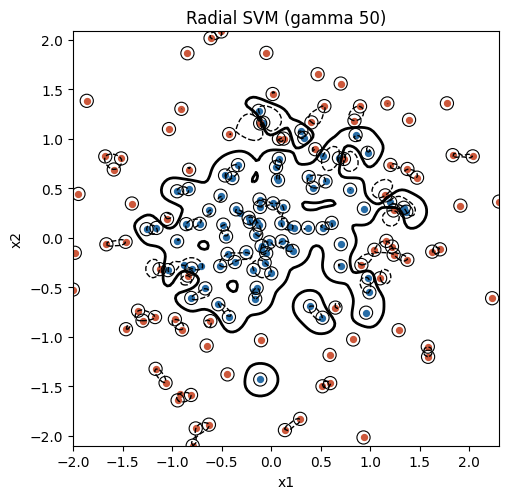

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
tegn_grense(mod_overtilp, train_ring, ax, "Radial SVM (gamma 50)")
plt.show()

**Slik leser du figuren:**
Grensen består av mange små lukkede kurver rundt enkeltpunkter.
Et nytt punkt som havner mellom øyene, klassifiseres nesten tilfeldig.

Vi ser også på forvekslingsmatrisen for den CV-valgte radiale modellen på testdata, med «Ring» som positiv klasse.

In [9]:
pd.crosstab(pd.Series(y_test, name="faktisk"),
            pd.Series(cv_radial.predict(X_test), name="predikert"))

predikert,Ring,Sentrum
faktisk,,
Ring,27,9
Sentrum,5,31


**Slik leser du output:**
Av de 36 ringpunktene ble 27 riktig klassifisert, så sensitiviteten er $27/36 = 0{,}75$.
Av de 36 sentrumspunktene ble 31 riktig klassifisert, så spesifisiteten er $31/36 \approx 0{,}86$.
Til sammen $58/72 \approx 0{,}81$ riktige, som i tabellen over.

## 5. Kjernetrikset regnet ut for hånd

En SVM med kjerne predikerer med
$$f(x) = \beta_0 + \sum_{i \in \mathcal S} \alpha_i K(x, x_i).$$
Vi regner ut dette selv for testdataene og sjekker at vi får samme svar som `decision_function()`.
Det viser at det ikke skjer noe mer enn det formelen sier.

Det vi trenger, ligger lagret i de to stegene i pipelinen:

- `skalerer.mean_` og `skalerer.scale_`: gjennomsnitt og standardavvik fra treningsdataene,
- `svm.support_vectors_`: støttevektorene $x_i$, på den *skalerte* skalaen,
- `svm.dual_coef_`: vektene $\alpha_i$, én per støttevektor,
- `svm.intercept_`: konstantleddet $\beta_0$,
- `svm.gamma`: verdien av $\gamma$.

In [10]:
mod = cv_radial.best_estimator_
skalerer = mod.named_steps["standardscaler"]   # Første steg i pipelinen
svm = mod.named_steps["svc"]                   # Andre steg i pipelinen

# Steg 1: Skaler testdata med treningsdataenes gjennomsnitt og standardavvik.
# Ellers sammenligner vi punkter på ulik skala
x_ny = skalerer.transform(X_test)

# Steg 2: Kvadrert avstand mellom hvert testpunkt og hver støttevektor.
# Vi bruker identiteten ||a - b||^2 = ||a||^2 + ||b||^2 - 2 a'b, som regner ut alle par på én gang.
# [:, None] og [None, :] gjør vektorene til en kolonne og en rad, slik at summen blir en matrise.
# Resultatet er en 72 x 83-matrise: én rad per testpunkt, én kolonne per støttevektor
SV = svm.support_vectors_
avstand2 = (x_ny**2).sum(axis=1)[:, None] + (SV**2).sum(axis=1)[None, :] - 2 * x_ny @ SV.T

# Steg 3: Radialkjernen K = exp(-gamma * avstand^2). Verdier nær 1 = like punkter, nær 0 = ulike
K = np.exp(-svm.gamma * avstand2)

# Steg 4: Vektet sum over støttevektorene pluss konstantledd: f(x) = sum_i alpha_i K(x, x_i) + beta_0
f_for_haand = K @ svm.dual_coef_.ravel() + svm.intercept_[0]

# Til sammenligning: beslutningsverdiene fra scikit-learn
f_sklearn = mod.decision_function(X_test)

print("Antall støttevektorer:", SV.shape[0])
print("Største avvik:        ", np.max(np.abs(f_for_haand - f_sklearn)))

Antall støttevektorer: 83
Største avvik:         1.4876988529977098e-14


**Slik leser du output:**
Modellen har 83 støttevektorer.
Største avvik mellom vår utregning og `decision_function()` er av størrelsesorden $10^{-14}$.
Det er bare avrundingsfeil i datamaskinen: de to utregningene er i praksis identiske.

Prediksjonen for et nytt punkt er en vektet sum av hvor *likt* punktet er hver av de 83 støttevektorene.
De andre 85 treningsobservasjonene er ikke med i summen i det hele tatt.

## 6. ROC-kurver og AUC

Vi skriver tre små hjelpefunksjoner i stedet for å bruke ferdige funksjoner, slik at det er tydelig hva som beregnes.

**`skaar()`** henter beslutningsverdien $f(x)$ og sørger for at høy verdi alltid betyr «Ring».
I `scikit-learn` betyr positiv $f(x)$ alltid den *andre* klassen i `classes_`, og klassene sorteres alfabetisk.
Her er `classes_` lik `['Ring', 'Sentrum']`, så positiv $f(x)$ betyr «Sentrum», og vi må snu fortegnet.

In [11]:
print(cv_radial.best_estimator_.classes_)


def skaar(mod, X, positiv="Ring"):
    f = mod.decision_function(X)
    return f if mod.classes_[1] == positiv else -f   # Snu fortegnet ved behov

['Ring' 'Sentrum']


**`roc_punkter()`** lager punktene på ROC-kurven.
Vi bruker hver observerte skår som terskel $c$ og sier «Ring» når skåren er minst $c$.
For hver terskel regner vi ut

- $FPR$: andelen sentrumspunkter som feilaktig blir kalt «Ring»,
- $TPR$ (sensitivitet): andelen ringpunkter som blir kalt «Ring».

In [12]:
def roc_punkter(s, y, positiv="Ring"):
    # Tersklene fra høyest til lavest. inf gir startpunktet (0, 0) der ingen kalles positiv
    terskler = np.sort(np.unique(np.append(s, np.inf)))[::-1]
    fpr = [np.mean(s[y != positiv] >= t) for t in terskler]   # Blant de negative
    tpr = [np.mean(s[y == positiv] >= t) for t in terskler]   # Blant de positive
    return np.array(fpr), np.array(tpr)

**`auc()`** bruker tolkningen av AUC direkte: sannsynligheten for at et tilfeldig positivt punkt får høyere skår enn et tilfeldig negativt.
Vi sammenligner *alle* par av ett positivt og ett negativt punkt (på testdata $36 \times 36 = 1296$ par) og teller andelen der det positive punktet har høyest skår.
Like skårer teller som et halvt.

In [13]:
def auc(s, y, positiv="Ring"):
    s_pos = s[y == positiv]   # Skårer for de positive
    s_neg = s[y != positiv]   # Skårer for de negative
    # s_pos[:, None] > s_neg[None, :] lager en tabell med alle par, som outer() i R
    return np.mean((s_pos[:, None] > s_neg[None, :]) + 0.5 * (s_pos[:, None] == s_neg[None, :]))


# Kontroll mot scikit-learns ferdige funksjon: de to skal gi samme tall
s_test = skaar(cv_radial.best_estimator_, X_test)
print("Vår auc():     ", round(auc(s_test, y_test), 4))
print("roc_auc_score():", round(roc_auc_score(y_test == "Ring", s_test), 4))

Vår auc():      0.9105
roc_auc_score(): 0.9105


Vår funksjon og `roc_auc_score()` gir samme tall.
Nå tegner vi ROC-kurvene for alle tre modellene, på trening og test.

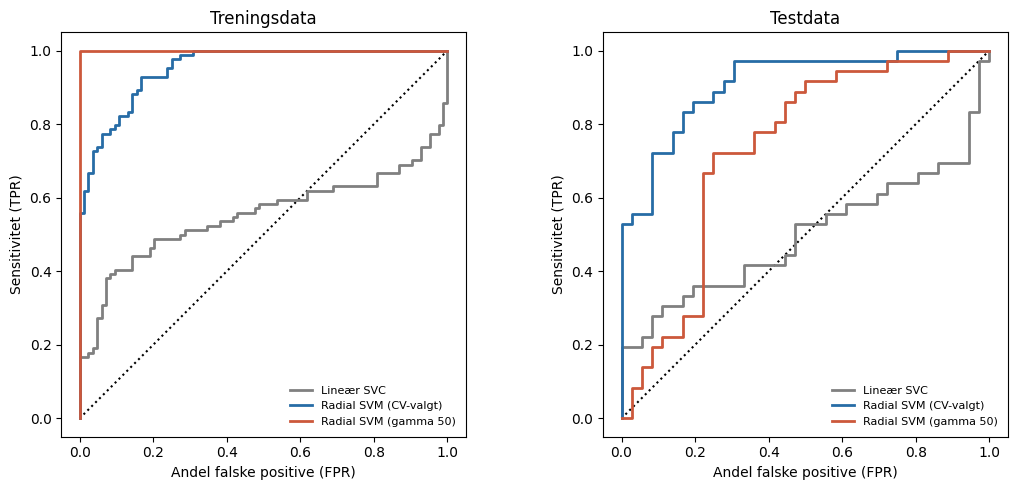

In [14]:
farger = ["grey", "#276ca6", "#cc583b"]
fig, akser = plt.subplots(1, 2, figsize=(11, 5))
for ax, (tittel, X, y) in zip(akser, [("Treningsdata", X_train, y_train),
                                      ("Testdata", X_test, y_test)]):
    ax.plot([0, 1], [0, 1], ":", color="black")   # Diagonalen: tilfeldig gjetting
    for (navn, m), farge in zip(modeller.items(), farger):
        fpr, tpr = roc_punkter(skaar(m, X), y)
        ax.plot(fpr, tpr, color=farge, linewidth=2, label=navn)
    ax.set_aspect("equal")
    ax.set_xlabel("Andel falske positive (FPR)")
    ax.set_ylabel("Sensitivitet (TPR)")
    ax.set_title(tittel)
    ax.legend(loc="lower right", frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Slik leser du figuren:**
En god modell har en kurve som går raskt opp mot øvre venstre hjørne: mange ringpunkter oppdages før mange sentrumspunkter blir feilaktig flagget.
Den stiplede diagonalen er tilfeldig gjetting.

På *treningsdata* (venstre) ser modellen med `gamma = 50` (rød) perfekt ut: kurven går rett opp til hjørnet.
På *testdata* (høyre) faller den kraftig og ligger klart under den CV-valgte modellen.
Den CV-valgte radiale modellen (blå) holder seg godt på begge.
Den lineære modellen (grå) ligger nær diagonalen på begge, fordi en rett linje ikke kan rangere punkter etter avstand fra sentrum.

In [15]:
pd.DataFrame({
    "AUC_trening": [round(auc(skaar(m, X_train), y_train), 3) for m in modeller.values()],
    "AUC_test": [round(auc(skaar(m, X_test), y_test), 3) for m in modeller.values()],
}, index=modeller.keys())

,AUC_trening,AUC_test
Lineær SVC,0.553,0.498
Radial SVM (CV-valgt),0.954,0.910
Radial SVM (gamma 50),1.000,0.733


**Slik leser du output:**

- **Lineær SVC:** AUC 0,553 på trening og 0,498 på test, altså ikke bedre enn tilfeldig.
- **Radial SVM (CV-valgt):** AUC 0,954 på trening og 0,910 på test. I 91 % av parene på testdata får ringpunktet høyest skår.
- **Radial SVM (gamma 50):** AUC 1,000 på trening, men bare 0,733 på test.

Rangeringen på treningsdata er altså et svært dårlig mål på hvordan modellen fungerer på nye data, nøyaktig som i hjertedataene i video 9.4.

## 7. Hengseltap og logistisk tap

Begge metodene kan skrives som «tap + straff».
Vi plotter tapet for én observasjon som funksjon av $y_i f(x_i)$:
positive verdier betyr riktig side av grensen, og jo større, desto lenger inn på riktig side.

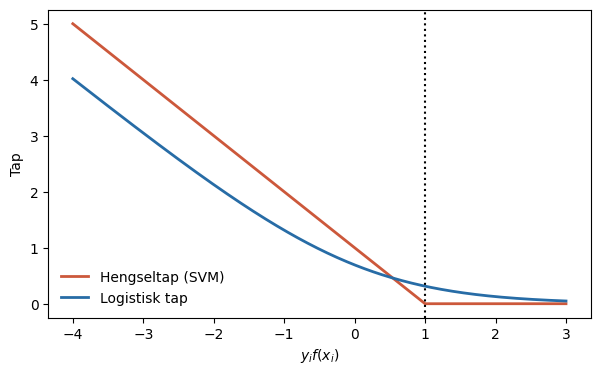

In [16]:
z = np.linspace(-4, 3, 400)   # Verdier av y*f(x)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(z, np.maximum(0, 1 - z), color="#cc583b", linewidth=2, label="Hengseltap (SVM)")   # max(0, 1 - z)
ax.plot(z, np.log(1 + np.exp(-z)), color="#276ca6", linewidth=2, label="Logistisk tap")    # log(1 + e^(-z))
ax.axvline(1, linestyle=":", color="black")   # Marginen: y*f(x) = 1
ax.set_xlabel(r"$y_i f(x_i)$")
ax.set_ylabel("Tap")
ax.legend(frameon=False)
plt.show()

**Slik leser du figuren:**
Til venstre, der observasjonen ligger på feil side, stiger begge tapene omtrent lineært og ligner hverandre.
Den viktige forskjellen er til høyre for den stiplede linjen.
Hengseltapet er *nøyaktig null* for alle observasjoner som ligger utenfor marginen ($y_i f(x_i) \ge 1$), så de påvirker ikke løsningen.
Det logistiske tapet blir mindre og mindre, men aldri null, så alle observasjoner påvirker en logistisk regresjon litt.
Knekkpunktet ved 1 er grunnen til at SVM har støttevektorer.

## 8. Logistisk regresjon med kvadratledd

Kan en vanlig logit gjøre jobben hvis vi gir den de riktige variablene?
Vi legger til $x_1^2$, $x_2^2$ og $x_1x_2$, akkurat som i avsnittet om utvidelse av prediktorene.

Vi bruker `statsmodels`, som har en formelsyntaks nesten lik `glm()` i R.
`I()` forteller at `**` (opphøyd i) og `*` skal regnes ut som vanlig aritmetikk, ikke tolkes som formelsyntaks.
`smf.logit()` vil ha utfallet som 0/1, så vi lager variabelen `ring` (1 = Ring, 0 = Sentrum).

Vi bruker `statsmodels` og ikke `LogisticRegression()` fra `scikit-learn`, fordi den siste legger på en straff (regularisering) som standard.
Da ville ikke koeffisientene vært de samme som i en vanlig logit.

In [17]:
logit_kv = smf.logit(
    "ring ~ x1 + x2 + I(x1**2) + I(x2**2) + I(x1*x2)",
    data=train_ring.assign(ring=(train_ring["y"] == "Ring").astype(int)),
).fit(disp=0)   # disp=0 skjuler meldinger fra optimeringen

logit_kv.params.round(2)

Intercept    -4.19
x1           -0.06
x2           -0.30
I(x1 ** 2)    3.05
I(x2 ** 2)    3.41
I(x1 * x2)   -0.37
dtype: float64

**Slik leser du output:**
Kvadratleddene $x_1^2$ (3,05) og $x_2^2$ (3,41) er store og positive, mens de lineære leddene og samspillsleddet er små.
Jo lenger fra origo et punkt ligger, desto høyere er altså sannsynligheten for «Ring».
Beslutningsgrensen ligger der logit-indeksen er null, omtrent der $3{,}05\,x_1^2 + 3{,}41\,x_2^2 \approx 4{,}19$.
Det er en ellipse som er nesten en sirkel med radius rundt 1,1–1,2, i overlappssonen vi simulerte (0,9–1,2).

Ønsker du hele regresjonstabellen med standardfeil, slik som `summary()` i R, bruk `print(logit_kv.summary())`.

In [18]:
# predict() gir sannsynligheter P(Ring | x)
p_test = logit_kv.predict(test_ring).to_numpy()

pd.DataFrame({
    # Logit: klassifiser som «Ring» når sannsynligheten er over 0,5
    "testnoyaktighet": [round(np.mean(np.where(p_test > 0.5, "Ring", "Sentrum") == y_test), 3),
                        round(treff(cv_radial.best_estimator_, X_test, y_test), 3)],
    # AUC kan regnes med sannsynligheter eller skårer: bare rangeringen teller
    "AUC_test": [round(auc(p_test, y_test), 3),
                 round(auc(skaar(cv_radial.best_estimator_, X_test), y_test), 3)],
}, index=["Logit med kvadratledd", "Radial SVM (CV-valgt)"])

,testnoyaktighet,AUC_test
Logit med kvadratledd,0.806,0.917
Radial SVM (CV-valgt),0.806,0.910


**Slik leser du output:**
Logit med kvadratledd gjør det like godt som den radiale SVM-en: begge har 81 % riktig, og AUC er 0,92 mot 0,91.
Med bare 72 testobservasjoner er forskjellen i AUC alt for liten til å kåre en vinner.

Men legg merke til *hvorfor* logit gjør det så godt: vi visste at dataene lå i en ring, fordi vi simulerte dem selv, og kunne derfor velge akkurat de riktige transformasjonene.
Med virkelige data og mange prediktorer vet vi sjelden det.
Da er kjernen nyttig: den finner en fleksibel grense uten at vi må gjette transformasjonene.
Til gjengjeld gir logit oss sannsynligheter og koeffisienter som kan tolkes, og det gjør ikke SVM-en.